In [ ]:
import numpy as np
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split

In [ ]:
(X_train_full, y_train_full), (X_test, y_test) = mnist.load_data()

In [ ]:
# Split off 10,000 for validation (same call as the whole team)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=10000, random_state=42, stratify=y_train_full
)

In [ ]:
# Normalize to 0-1
X_train = X_train.astype("float32") / 255.0
X_val   = X_val.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

In [ ]:
# CNN shape: add a channel dimension (28, 28, 1)
X_train_cnn = X_train.reshape(len(X_train), 28, 28, 1)
X_val_cnn   = X_val.reshape(len(X_val), 28, 28, 1)
X_test_cnn  = X_test.reshape(len(X_test), 28, 28, 1)

In [ ]:
print("Train:", X_train_cnn.shape, "Val:", X_val_cnn.shape, "Test:", X_test_cnn.shape)
print("Pixel range:", X_train_cnn.min(), "to", X_train_cnn.max())

Train: (50000, 28, 28, 1) Val: (10000, 28, 28, 1) Test: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers

def build_cnn(filters1, filters2):
    model = keras.Sequential([                                   # Sequential = layers stacked in order
        keras.Input(shape=(28, 28, 1)),                          # input: 28x28 grayscale image
        layers.Conv2D(filters1, (3, 3), activation="relu"),      # stage 1: slide 3x3 filters, ReLU
        layers.MaxPooling2D((2, 2)),                             # keep the max of each 2x2 block
        layers.Conv2D(filters2, (3, 3), activation="relu"),      # stage 2
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),                                        # feature maps -> one long row
        layers.Dense(64, activation="relu"),                     # fully connected layer, 64 neurons
        layers.Dense(10, activation="softmax"),                  # 10 outputs: one probability per digit
    ])
    return model

model = build_cnn(16, 32)    # experiment A: 16 filters, then 32
model.summary()              # print the layers, output shapes and parameter counts

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,714 (221.54 KB)

 Trainable params: 56,714 (221.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import time
from tensorflow.keras.callbacks import ModelCheckpoint

# 1. Compile: tell Keras how to learn
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),   # is the loss for multi-class problems. "Sparse" means our labels are plain numbers (0–9)
    loss="sparse_categorical_crossentropy",                  # how wrong the probabilities are
    metrics=["accuracy"]                                     # also report % correct
)

# 2. Checkpoint: save the model whenever validation loss reaches a new low
checkpoint = ModelCheckpoint(
    "cnn_A.keras",           # file to write
    monitor="val_loss",      # watch the validation loss

)

In [ ]:
# 3. Train
start = time.time()
history = model.fit(
    X_train_cnn, y_train,                     # learn from the 50,000 training images
    validation_data=(X_val_cnn, y_val),       # measure (but not learn from) the 10,000 validation images
    epochs=10,                                # up to 10 passes over the training data
    batch_size=128,                           # adjust the weights after every 128 images
    callbacks=[checkpoint]                    # run the checkpoint after each epoch
)
train_time = time.time() - start
print("Training time (s):", round(train_time, 1))

Epoch 1/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.9071 - loss: 0.3229 - val_accuracy: 0.9666 - val_loss: 0.1130
Epoch 2/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9738 - loss: 0.0842 - val_accuracy: 0.9789 - val_loss: 0.0703
Epoch 3/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9817 - loss: 0.0585 - val_accuracy: 0.9825 - val_loss: 0.0637
Epoch 4/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9854 - loss: 0.0468 - val_accuracy: 0.9822 - val_loss: 0.0593
Epoch 5/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9881 - loss: 0.0389 - val_accuracy: 0.9818 - val_loss: 0.0650
Epoch 6/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9900 - loss: 0.0323 - val_accuracy: 0.9857 - val_loss: 0.0497
Epoch 7/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9914 - loss: 0.0277 - val_accuracy: 0.9847 - val_loss: 0.0545
Epoch 8/10
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9933 - loss: 0.0230 - val_accuracy: 0

In [ ]:
import numpy as np

results = {}     # will hold the numbers for each experiment
histories = {}   # will hold the loss curves for each experiment

def run_cnn(name, filters1, filters2, lr):
    keras.utils.set_random_seed(42)                 # fix the randomness so results can be repeated
    model = build_cnn(filters1, filters2)           # the same recipe as before
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    checkpoint = ModelCheckpoint(f"cnn_{name}.keras", monitor="val_loss", save_best_only=True)

    start = time.time()
    history = model.fit(
        X_train_cnn, y_train,
        validation_data=(X_val_cnn, y_val),
        epochs=10, batch_size=128,
        callbacks=[checkpoint],
        verbose=0                                   # don't print every epoch (we'll print a summary)
    )
    train_time = time.time() - start

    best_epoch = int(np.argmin(history.history["val_loss"]))      # index of the lowest validation loss
    best_val_acc = history.history["val_accuracy"][best_epoch]     # validation accuracy at that epoch

    print(f"Experiment {name}: filters={filters1},{filters2}  lr={lr}")
    print(f"  Best epoch: {best_epoch + 1}   Val loss: {history.history['val_loss'][best_epoch]:.4f}   "
          f"Val acc: {best_val_acc:.4f}   Train time: {train_time:.1f}s")

    histories[name] = history.history
    results[name] = (best_epoch + 1, best_val_acc, train_time)

run_cnn("A", 16, 32, 0.001)
run_cnn("B", 32, 64, 0.001)
run_cnn("C", 16, 32, 0.0003)

Experiment A: filters=16,32  lr=0.001
  Best epoch: 10   Val loss: 0.0510   Val acc: 0.9859   Train time: 23.7s
Experiment B: filters=32,64  lr=0.001
  Best epoch: 7   Val loss: 0.0444   Val acc: 0.9882   Train time: 29.3s
Experiment C: filters=16,32  lr=0.0003
  Best epoch: 10   Val loss: 0.0564   Val acc: 0.9835   Train time: 24.4s


#  plot the loss curves

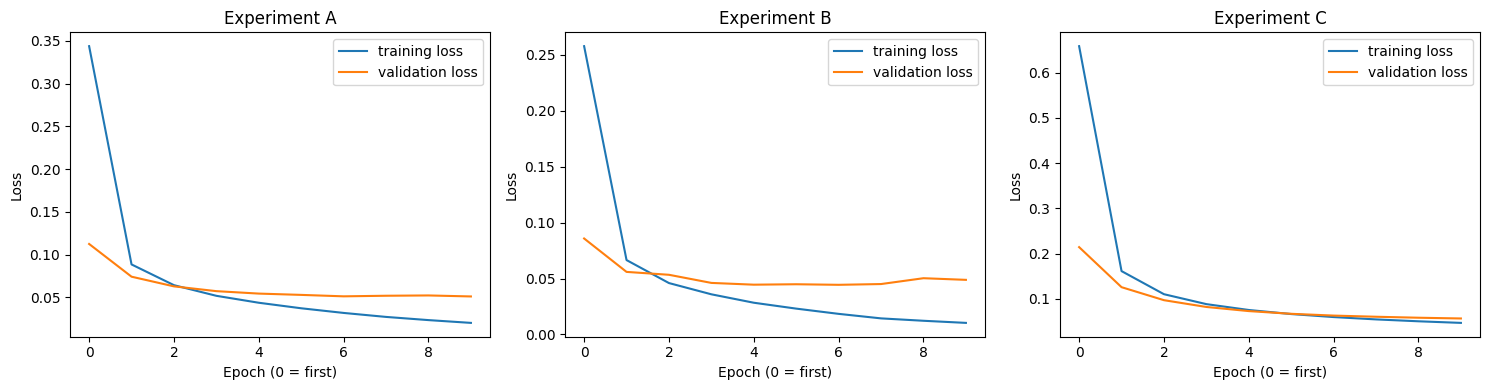

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))      # 3 plots side by side

for ax, name in zip(axes, ["A", "B", "C"]):
    h = histories[name]
    ax.plot(h["loss"], label="training loss")          # how wrong on the images it learns from
    ax.plot(h["val_loss"], label="validation loss")    # how wrong on the unseen validation images
    ax.set_title(f"Experiment {name}")
    ax.set_xlabel("Epoch (0 = first)")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import os

# 1. Load the BEST checkpoint of experiment B (epoch 7), not the model as it ended
best_cnn = keras.models.load_model("cnn_B.keras")

# 2. Score it on the sealed test set (first time we touch it)
start = time.time()
test_probs = best_cnn.predict(X_test_cnn, verbose=0)    # 10,000 rows of 10 probabilities
infer_time = time.time() - start
test_pred = np.argmax(test_probs, axis=1)               # the digit with the highest probability
test_acc = (test_pred == y_test).mean()                 # share of correct predictions

# 3. Save it under the final name and check the size
best_cnn.save("cnn_final.keras")
size_mb = os.path.getsize("cnn_final.keras") / (1024 * 1024)

print("Test accuracy:", round(float(test_acc), 4))
print("Predicting 10,000 images took (s):", round(infer_time, 2))
print("File size (MB):", round(size_mb, 2))

Test accuracy: 0.9901
Predicting 10,000 images took (s): 2.23
File size (MB): 1.43


In [ ]:
from google.colab import files
files.download("cnn_final.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>